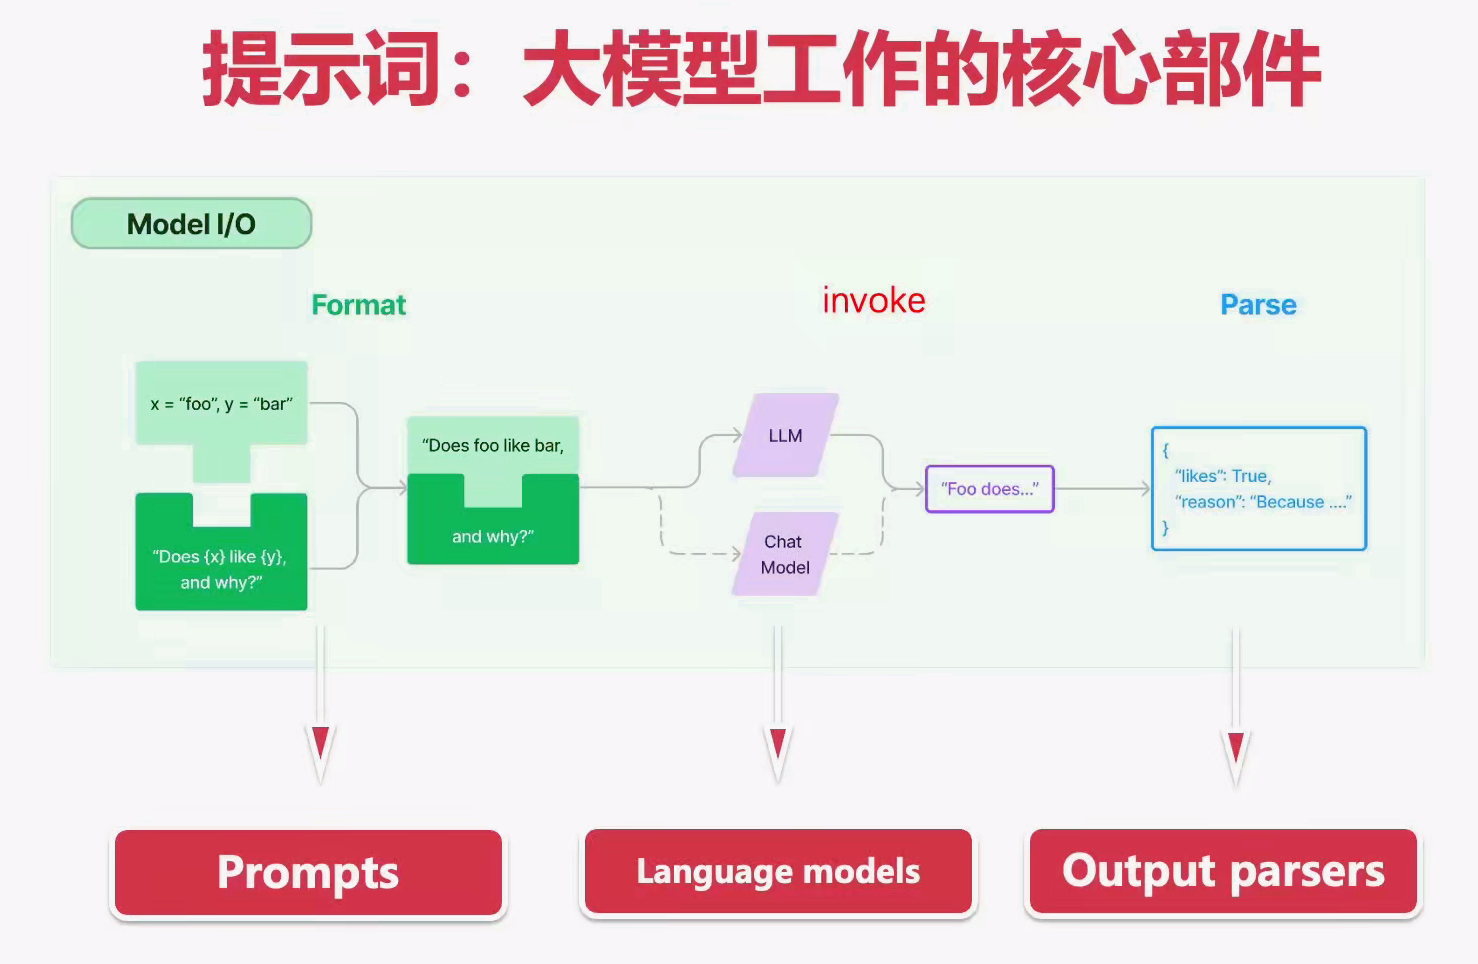
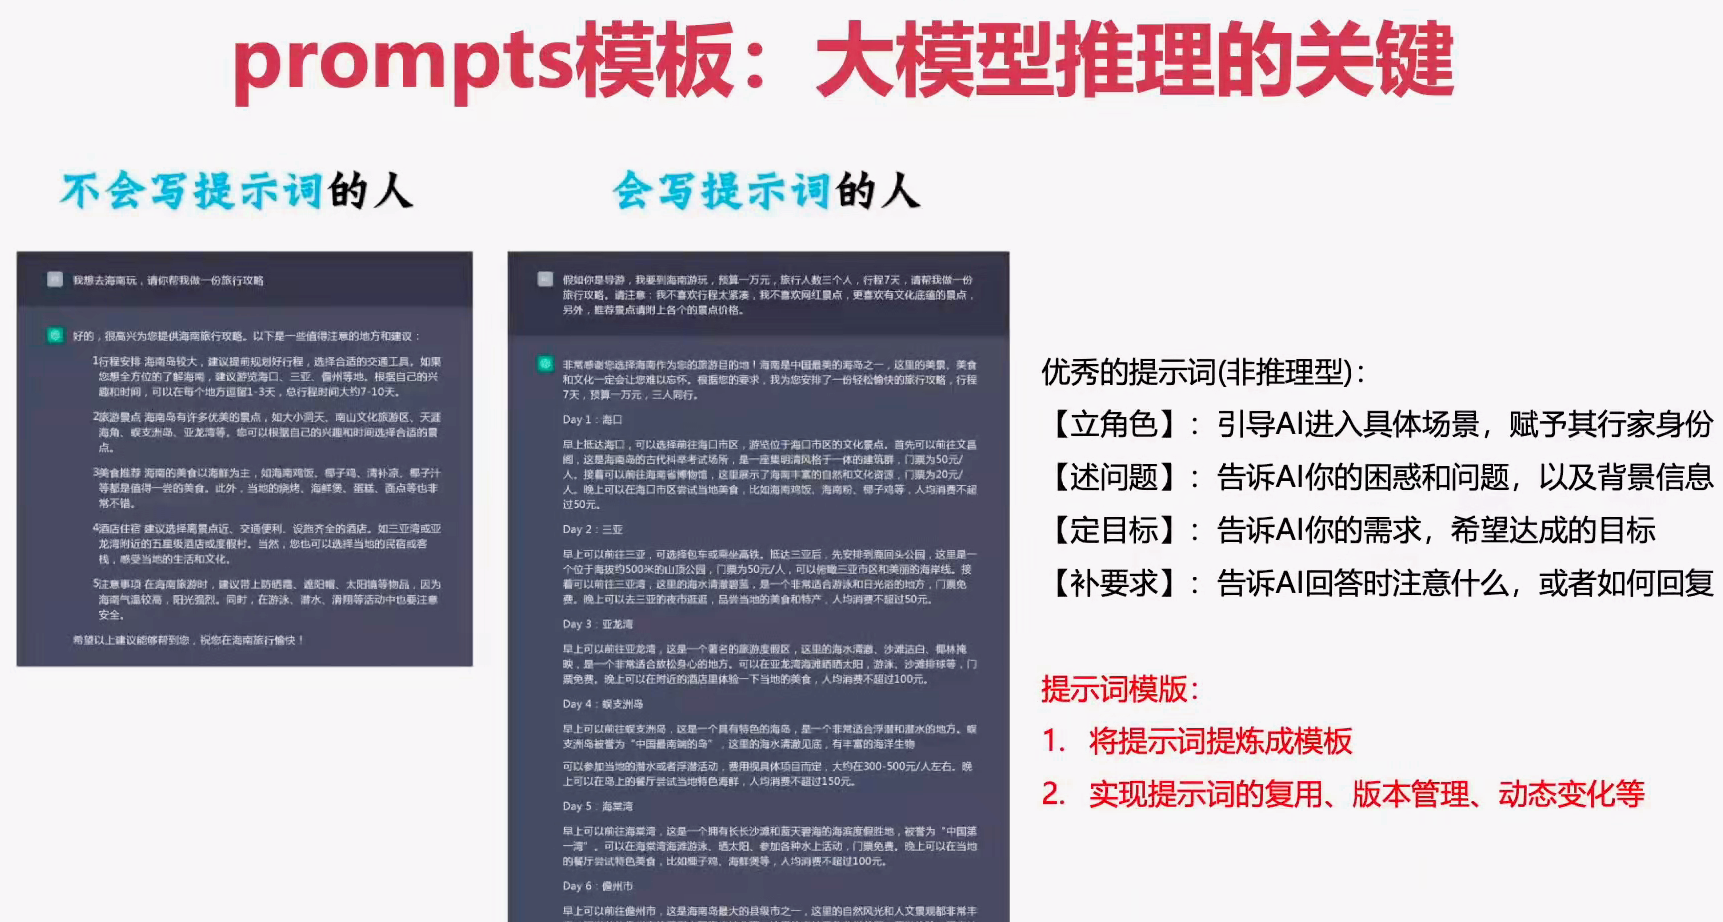

### Prompts 模板实战
---
- 字符串模板 - PromptTemplate
- 对话模板 - ChatPromptTemplate
- 消息占位符
- 使用Message组合模板
- 自定义提示词模板

In [1]:
# 字符模板
# string template
from langchain_core.prompts import PromptTemplate

prompt = PromptTemplate.from_template("你是一个{name},帮我起一个具有{county}特色的{sex}名字")
prompts = prompt.format(name="算命大师", county="法国", sex="女孩")
print(prompts)

你是一个算命大师,帮我起一个具有法国特色的女孩名字


In [2]:
# 对话模板具有结构，chatmodels
# chat template with structure
from langchain_core.prompts import ChatPromptTemplate

chat_template = ChatPromptTemplate.from_messages(
    [
        ("system", "你是一个起名大师，你的名字叫{name}"),
        ("human", "你好{name},你感觉如何？"),
        ("ai", "你好！我状态非常好！"),
        ("human", "你叫什么名字呢？"),
        ("ai", "你好！我叫{name}"),
        ("human", "{user_input}"),
    ]
)

chats = chat_template.format_messages(name="陈大师", user_input="你的爸爸是谁呢？")
print(chats)

[SystemMessage(content='你是一个起名大师，你的名字叫陈大师', additional_kwargs={}, response_metadata={}), HumanMessage(content='你好陈大师,你感觉如何？', additional_kwargs={}, response_metadata={}), AIMessage(content='你好！我状态非常好！', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='你叫什么名字呢？', additional_kwargs={}, response_metadata={}), AIMessage(content='你好！我叫陈大师', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='你的爸爸是谁呢？', additional_kwargs={}, response_metadata={})]


In [13]:
# 消息占位符
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
from langchain_core.messages import HumanMessage

prompt_template = ChatPromptTemplate([
    ("system", "你是一个厉害的人工智能助手"),
    # MessagesPlaceholder("msgs"),
    ("placeholder", "{msgs}")
])

result = prompt_template.invoke({"msgs": [HumanMessage(content="hi!")]})
print(result)

messages=[SystemMessage(content='你是一个厉害的人工智能助手', additional_kwargs={}, response_metadata={}), HumanMessage(content='hi!', additional_kwargs={}, response_metadata={})]


In [14]:
# Message组合模板
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage

# 直接创建消息
# create messages directly
system = SystemMessage(
    content="你是一个起名大师",
    additional_kwargs= {"大师姓名": "陈瞎子"}
)

human = HumanMessage(
    content="请问大师叫什么？" 
)

ai = AIMessage(
    content="我叫陈瞎子"
)

[system, human, ai]

[SystemMessage(content='你是一个起名大师', additional_kwargs={'大师姓名': '陈瞎子'}, response_metadata={}),
 HumanMessage(content='请问大师叫什么？', additional_kwargs={}, response_metadata={}),
 AIMessage(content='我叫陈瞎子', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[])]

In [ ]:
# 自定义提示词模板

# 函数大师： 根据函数名称，查找函数代码，并给出中文代码说明
# Function Master: Given a function name, find the function code and provide a Chinese code explanation
from langchain_core.prompts import StringPromptTemplate

# 定义一个建档的函数作为示例效果
# Define a simple function as an example
def hello_world(abc):
    print("Hello, world!")
    return abc

PROMPT = """\
你是一个非常有经验和天赋的程序员，现在给你如下函数名称，你会按照如下格式，输出这段代码的名称、源代码、中文解释。
函数名称：{function_name}
源代码：
{source_code}
代码解释：
"""

import inspect

def get_source_code(function_name):
    # 获得源代码
    # Get the source code
    return inspect.getsource(function_name)

# 自定义的模板class
# Custom template class
class CustomPrompt(StringPromptTemplate):

    def format(self, **kwargs) -> str:
        # 获得源代码
        # Get the source code 获得函数名
        source_code = get_source_code(kwargs["function_name"])

        # 生成提示词模板
        # Generate the prompt template
        prompt = PROMPT.format(
            function_name=kwargs["function_name"].__name__, source_code=source_code
        )
        return prompt

# 使用自定义的提示词模板，而不是类似对话提示词模板
a = CustomPrompt(input_variables=["function_name"])
pm = a.format(function_name=hello_world)
print("格式化之后的提示词为=====>")
print(pm)

# 和LLM连接起来
# Connect to LLM
from langchain_openai import OpenAI
import os

from dotenv import load_dotenv

load_dotenv()

from langchain_openai import ChatOpenAI
import os
from dotenv import load_dotenv
load_dotenv()

model = ChatOpenAI(
    model="Qwen/Qwen3.8-27B",  # 模型名称          
    api_key=os.getenv("api_key"),  # 在环境变量中设置的API Key
    base_url=os.getenv("base_url"), # 在环境变量中设置的API请求地址
    temperature=0,
)

msg = model.invoke(pm)
print(msg.content)

格式化之后的提示词为====>
你是一个非常有经验和天赋的程序员，现在给你如下函数名称，你会按照如下格式，输出这段代码的名称、源代码、中文解释。
函数名称：hello_world
源代码：
def hello_world(abc):
    print("Hello, world!")
    return abc

代码解释：



函数名称：hello_world

源代码：
```python
def hello_world(abc):
    print("Hello, world!")
    return abc
```

代码解释：
该函数名为 `hello_world`，接收一个参数 `abc`。函数执行时会先打印字符串 `"Hello, world!"`，然后返回传入的参数 `abc`。
